# ParFlow Short Course: Overland Flow
## Exercise: Runoff generation mechanisms

### Problem Description
The notebook uses a simple hillslope domain to illustrate runoff generation for infiltraton excess conditions. See the image below for more details on the baseline problem setup. In the Exercises that follow you will modify the simulation to explore other runoff mechanisms. 

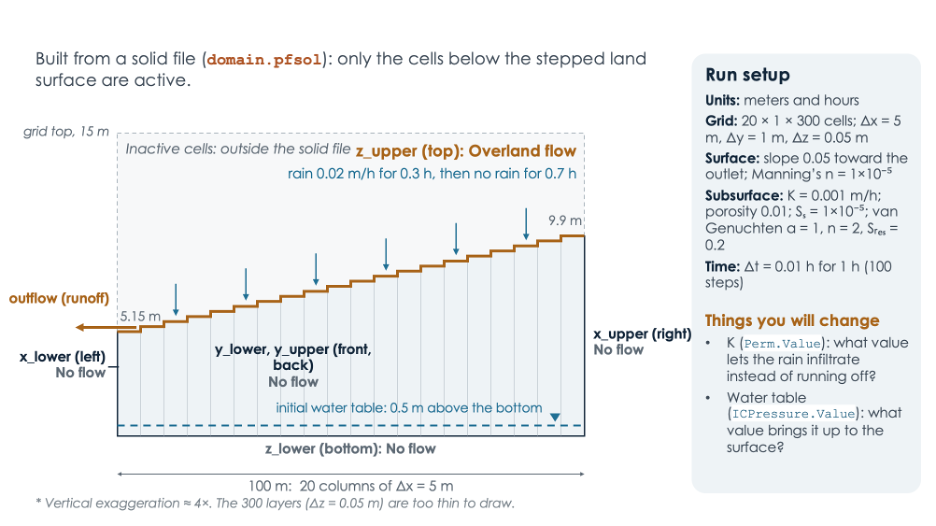


## 1. Setting up the baseline simulation for Dunne flow


In [ ]:
#  This script can be configured to run either a Hortonian or Dunne flow example
# using ParFlow. It is configured to run using the orthogonal grid
# using a PFSOLID file and to output total runoff.

# R. Maxwell, originally developed in 2009, updated PF Short Course 2019, updated to Python and Jupyter 2022
# reedmaxwell@princeton.edu

import os
from parflow import Run
from parflow.tools.fs import get_absolute_path, cp, rm, mkdir, exists
import numpy as np
import parflow as pf
from glob import glob
import matplotlib.pyplot as plt


# set up directories
pf_runname = 'dunne_over'
base = os.path.join(os.getcwd(), "overland_hillslope_runs", pf_runname)
Dunne = Run(pf_runname)
mkdir(base)

#Copy the solid file into the run directory
cp('./domain.pfsol', base+ '/domain.pfsol')


#Set file viersion and processor topology
Dunne.FileVersion = 4

Dunne.Process.Topology.P = 1
Dunne.Process.Topology.Q = 1
Dunne.Process.Topology.R = 1

#---------------------------------------------------------
# Computational Grid
#---------------------------------------------------------
Dunne.ComputationalGrid.Lower.X = 0.0
Dunne.ComputationalGrid.Lower.Y = 0.0
Dunne.ComputationalGrid.Lower.Z = 0.0

Dunne.ComputationalGrid.NX = 20
Dunne.ComputationalGrid.NY = 1
Dunne.ComputationalGrid.NZ = 300

Dunne.ComputationalGrid.DX = 5.0
Dunne.ComputationalGrid.DY = 1.0
Dunne.ComputationalGrid.DZ = .05

#---------------------------------------------------------
# Domain Geometry
#---------------------------------------------------------
Dunne.GeomInput.Names = 'solidinput1'

Dunne.GeomInput.solidinput1.InputType = 'SolidFile'
Dunne.GeomInput.solidinput1.GeomNames = 'domain'
Dunne.GeomInput.solidinput1.FileName = 'domain.pfsol'

Dunne.Geom.domain.Patches = 'z_upper x_lower y_lower x_upper y_upper z_lower'

#-----------------------------------------------------------------------------
# Perm
#-----------------------------------------------------------------------------

Dunne.Geom.Perm.Names = 'domain'

# Values in m/hour

Dunne.Geom.domain.Perm.Type = 'Constant'
Dunne.Geom.domain.Perm.Value = 0.001

Dunne.Perm.TensorType = 'TensorByGeom'

Dunne.Geom.Perm.TensorByGeom.Names = 'domain'

Dunne.Geom.domain.Perm.TensorValX = 1.0
Dunne.Geom.domain.Perm.TensorValY = 1.0
Dunne.Geom.domain.Perm.TensorValZ = 1.0

#-----------------------------------------------------------------------------
# Specific Storage
#-----------------------------------------------------------------------------

Dunne.SpecificStorage.Type = 'Constant'
Dunne.SpecificStorage.GeomNames = 'domain'
Dunne.Geom.domain.SpecificStorage.Value = 1.0e-5

#-----------------------------------------------------------------------------
# Phases
#-----------------------------------------------------------------------------

Dunne.Phase.Names = 'water'

Dunne.Phase.water.Density.Type = 'Constant'
Dunne.Phase.water.Density.Value = 1.0

Dunne.Phase.water.Viscosity.Type = 'Constant'
Dunne.Phase.water.Viscosity.Value = 1.0

#-----------------------------------------------------------------------------
# Contaminants
#-----------------------------------------------------------------------------

Dunne.Contaminants.Names = ''

#-----------------------------------------------------------------------------
# Retardation
#-----------------------------------------------------------------------------

Dunne.Geom.Retardation.GeomNames = ''

#-----------------------------------------------------------------------------
# Gravity
#-----------------------------------------------------------------------------

Dunne.Gravity = 1.0

#-----------------------------------------------------------------------------
# Setup timing info
#-----------------------------------------------------------------------------

# run for 1 hours @ 0.01hr timesteps
Dunne.TimingInfo.BaseUnit = 0.01
Dunne.TimingInfo.StartCount = 0
Dunne.TimingInfo.StartTime = 0.0
Dunne.TimingInfo.StopTime = 1.0
Dunne.TimingInfo.DumpInterval = -1
Dunne.TimeStep.Type = 'Constant'
Dunne.TimeStep.Value = 0.01

#-----------------------------------------------------------------------------
# Porosity
#-----------------------------------------------------------------------------

Dunne.Geom.Porosity.GeomNames = 'domain'
Dunne.Geom.domain.Porosity.Type = 'Constant'
Dunne.Geom.domain.Porosity.Value = 0.01

#-----------------------------------------------------------------------------
# Domain
#-----------------------------------------------------------------------------

Dunne.Domain.GeomName = 'domain'

#-----------------------------------------------------------------------------
# Relative Permeability
#-----------------------------------------------------------------------------

Dunne.Phase.RelPerm.Type = 'VanGenuchten'
Dunne.Phase.RelPerm.GeomNames = 'domain'

Dunne.Geom.domain.RelPerm.Alpha = 1.0
Dunne.Geom.domain.RelPerm.N = 2.

#---------------------------------------------------------
# Saturation
#---------------------------------------------------------

Dunne.Phase.Saturation.Type = 'VanGenuchten'
Dunne.Phase.Saturation.GeomNames = 'domain'

Dunne.Geom.domain.Saturation.Alpha = 1.0
Dunne.Geom.domain.Saturation.N = 2.
Dunne.Geom.domain.Saturation.SRes = 0.2
Dunne.Geom.domain.Saturation.SSat = 1.0

#-----------------------------------------------------------------------------
# Wells
#-----------------------------------------------------------------------------
Dunne.Wells.Names = ''

#-----------------------------------------------------------------------------
# Time Cycles
#-----------------------------------------------------------------------------
Dunne.Cycle.Names = 'constant rainrec'
Dunne.Cycle.constant.Names = 'alltime'
Dunne.Cycle.constant.alltime.Length = 1
Dunne.Cycle.constant.Repeat = -1

# rainfall and recession time periods are defined here
# rain for 0.3 hours, recession for 0.7 hours (change to rain for a different time)
# this is a function of the BaseUnit set above, that is each length
# is an integer mulitplier of that value.  The BaseUnit happens to be equal
# to our timestep but that need not be the case, it's just good practice

Dunne.Cycle.rainrec.Names = 'rain rec'
Dunne.Cycle.rainrec.rain.Length = 30
Dunne.Cycle.rainrec.rec.Length = 70
Dunne.Cycle.rainrec.Repeat = -1


#-----------------------------------------------------------------------------
# Boundary Conditions: Pressure
#-----------------------------------------------------------------------------
# specify patches as a list for BC's
Dunne.BCPressure.PatchNames = 'z_upper x_lower y_lower x_upper y_upper z_lower'

Dunne.Patch.x_lower.BCPressure.Type = 'FluxConst'
Dunne.Patch.x_lower.BCPressure.Cycle = 'constant'
Dunne.Patch.x_lower.BCPressure.alltime.Value = 0.0

Dunne.Patch.y_lower.BCPressure.Type = 'FluxConst'
Dunne.Patch.y_lower.BCPressure.Cycle = 'constant'
Dunne.Patch.y_lower.BCPressure.alltime.Value = 0.0

Dunne.Patch.z_lower.BCPressure.Type = 'FluxConst'
Dunne.Patch.z_lower.BCPressure.Cycle = 'constant'
Dunne.Patch.z_lower.BCPressure.alltime.Value = 0.0

Dunne.Patch.x_upper.BCPressure.Type = 'FluxConst'
Dunne.Patch.x_upper.BCPressure.Cycle = 'constant'
Dunne.Patch.x_upper.BCPressure.alltime.Value = 0.0

Dunne.Patch.y_upper.BCPressure.Type = 'FluxConst'
Dunne.Patch.y_upper.BCPressure.Cycle = 'constant'
Dunne.Patch.y_upper.BCPressure.alltime.Value = 0.0

## overland flow boundary condition with very heavy rainfall then recession
Dunne.Patch.z_upper.BCPressure.Type = 'OverlandFlow'
Dunne.Patch.z_upper.BCPressure.Cycle = 'rainrec'
Dunne.Patch.z_upper.BCPressure.rain.Value = -0.02
Dunne.Patch.z_upper.BCPressure.rec.Value = 0.00

#---------------------------------------------------------
# Topo slopes in x-direction
#---------------------------------------------------------

Dunne.TopoSlopesX.Type = 'Constant'
Dunne.TopoSlopesX.GeomNames = 'domain'
Dunne.TopoSlopesX.Geom.domain.Value = 0.05

#---------------------------------------------------------
# Topo slopes in y-direction
#---------------------------------------------------------


Dunne.TopoSlopesY.Type = 'Constant'
Dunne.TopoSlopesY.GeomNames = 'domain'
Dunne.TopoSlopesY.Geom.domain.Value = 0.00

#---------------------------------------------------------
# Mannings coefficient
#---------------------------------------------------------

Dunne.Mannings.Type = 'Constant'
Dunne.Mannings.GeomNames = 'domain'
Dunne.Mannings.Geom.domain.Value = 1.e-5

#-----------------------------------------------------------------------------
# Phase sources:
#-----------------------------------------------------------------------------

Dunne.PhaseSources.water.Type = 'Constant'
Dunne.PhaseSources.water.GeomNames = 'domain'
Dunne.PhaseSources.water.Geom.domain.Value = 0.0

#-----------------------------------------------------------------------------
# Exact solution specification for error calculations
#-----------------------------------------------------------------------------

Dunne.KnownSolution = 'NoKnownSolution'


#-----------------------------------------------------------------------------
# Set solver parameters
#-----------------------------------------------------------------------------

Dunne.Solver = 'Richards'
Dunne.Solver.MaxIter = 2500

Dunne.Solver.Nonlinear.MaxIter = 300
Dunne.Solver.Nonlinear.ResidualTol = 1e-6
Dunne.Solver.Nonlinear.EtaChoice = 'Walker1'
Dunne.Solver.Nonlinear.EtaValue = 0.001
Dunne.Solver.Nonlinear.UseJacobian = False
#Dunne.Solver.Nonlinear.UseJacobian = True
Dunne.Solver.Nonlinear.DerivativeEpsilon = 1e-16
Dunne.Solver.Nonlinear.StepTol = 1e-20
Dunne.Solver.Nonlinear.Globalization = 'LineSearch'
Dunne.Solver.Linear.KrylovDimension = 20
Dunne.Solver.Linear.MaxRestart = 2

#Dunne.Solver.Linear.Preconditioner.PCMatrixType = 'FullJacobian'

Dunne.Solver.Linear.Preconditioner = 'MGSemi'
Dunne.Solver.PrintSubsurf = False
Dunne.Solver.Drop = 1E-20
Dunne.Solver.AbsTol = 1E-12

Dunne.Solver.PrintOverlandSum = True

# write out a lot of output as SILO Files
Dunne.Solver.WriteSiloSubsurfData = False
Dunne.Solver.WriteSiloPressure = False
Dunne.Solver.WriteSiloSaturation = False
Dunne.Solver.WriteSiloSlopes = False
Dunne.Solver.WriteSiloMask = False
Dunne.Solver.WriteSiloEvapTrans = False
Dunne.Solver.WriteSiloEvapTransSum = False
Dunne.Solver.WriteSiloOverlandSum = False
Dunne.Solver.WriteSiloMannings = False
Dunne.Solver.WriteSiloSpecificStorage = False

#---------------------------------------------------------
# Initial conditions: water pressure
#---------------------------------------------------------

# set water table to be level with the outlet of the domain
Dunne.ICPressure.Type = 'HydroStaticPatch'
Dunne.ICPressure.GeomNames = 'domain'
Dunne.Geom.domain.ICPressure.Value = 0.5

Dunne.Geom.domain.ICPressure.RefGeom = 'domain'
Dunne.Geom.domain.ICPressure.RefPatch = 'z_lower'

#--------
# Things that can be changed in the simulation to swap from Horton to Dunne flow
#--------

# increase the hydraulic conductivity
# if the K values are in m/h and the rainfall rate is 0.02 m/h what K is needed
# to create infiltration not overland flow? 
#Dunne.Geom.domain.Perm.Value = ?

# move the water table closer to the outlet, i.e. make it shallower
# if the initial pressure value is in meters from the bottom of the domain
# what value will create water table interactions?
#Dunne.Geom.domain.ICPressure.Value = ?

#-----------------------------------------------------------------------------
# Run and Unload the ParFlow output files
#-----------------------------------------------------------------------------

# create a subdirectory to run in, change to this directory
Dunne.run(working_directory=base)


## 1.2 Plotting the baseline run

This block plots a snapshot of saturation and the outflow hydrograph for the baseline run.  Outflow is in m$^2$/h per unit width against time in hours, the same units as your overland flow solutions.

The dashed curve is Manning's equation applied to the ponded depth at the outlet, as a check on ParFlow's own outflow.  The dotted line is the equilibrium flow for an impervious plane, $rL$.  To add your analytical or finite difference hydrograph, pass it in as `t_hw` (hours) and `q_hw` (m$^2$/h).

In [ ]:
import hillslope_tools as ht

pf_runname = "dunne_over"
run = ht.load_run(pf_runname)

# your own solution from the overland flow homework: time in hours, flow in m2/h
t_hw, q_hw = None, None

ht.plot_run(run, t_hw=t_hw, q_hw=q_hw)


## 1.3 Watching the baseline run

The movie shows three things through time: the saturation in the hillslope cross section with the water table, the depth of water ponded on the land surface, and the hydrograph at the outlet.  Where does water first pond, and where does it pond last?

In [ ]:
ht.movie(run)      # ht.movie(run, save="dunne_over.gif") also writes the movie to a file


## 2 Experiments

Part 2 of the project asks for two changes to the baseline: a higher hydraulic conductivity, and a shallower water table.  The cell below loads the baseline run, changes a value, and runs it under a new name.  Each run is kept in its own folder under `overland_hillslope_runs`, so you can come back to any of them.

## 2.1 Loading the baseline run and modifying to make a new run

In [ ]:
# sample code
# Import run information from pfidb
input_run = "dunne_over" #Set this to the name of the run you want to load
base = os.path.join(os.getcwd(), "overland_hillslope_runs", input_run )
baseline_run = Run.from_definition(os.path.join(base, f"{input_run}.pfidb"))

new_name = 'high_K' #This is the name you want to save your new run as
baseline_run.set_name(new_name)

# increase the hydraulic conductivity
# if the K values are in m/h and the rainfall rate is 0.02 m/h what K is needed
# to create infiltration not overland flow? 
#baseline_run.Geom.domain.Perm.Value = ?

# move the water table closer to the outlet, i.e. make it shallower
# if the initial pressure value is in meters from the bottom of the domain
# what value will create water table interactions?
#baseline_run.Geom.domain.ICPressure.Value = ?


#Make a directory for your new run and run it
run_dir = os.path.join(os.getcwd(), "overland_hillslope_runs", baseline_run.get_name() )
mkdir(run_dir)
cp('./domain.pfsol', run_dir+ '/domain.pfsol')
print(f"run_dir: {run_dir}")
baseline_run.run(working_directory=run_dir)

## 2.2 Plotting and watching a single run of your choosing

Select which run to show with the `pf_runname` variable.

In [ ]:
# Pick one of your previous runs to load, plot and watch
pf_runname = "high_K"
run = ht.load_run(pf_runname)
ht.plot_run(run, t_hw=t_hw, q_hw=q_hw)
ht.movie(run)


## 2.3 Plotting a set of runs

Set `run_names` in the next cell to the run names under `overland_hillslope_runs`.  The outlet hydrographs are plotted together.

In [ ]:
# Add or remove run names to compare their outlet hydrographs.
run_names = ["dunne_over", "high_K"]

ht.compare_runs(run_names, t_hw=t_hw, q_hw=q_hw)
